# **Neurodegenerative Disease Detection** 

> # **Creating Directories**
# *In this section, I set up the directories for training, validation, and test datasets. And also define paths to the original datasets for each condition.*

In [1]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
import shutil


def create_dir(directory):
    if not os.path.exists(directory):
        os.makedirs(directory)

# Define paths to your dataset
base_dir = '/kaggle/input/neurodegenerative-diseases'
normal_dir = os.path.join(base_dir, 'normal')
alzheimers_dir = os.path.join(base_dir, 'alzheimers_dataset')
parkinsons_dir = os.path.join(base_dir, 'parkinsons_dataset')

# Create train, validation, and test directories
output_base_dir = '/kaggle/working/processed_data'
train_dir = os.path.join(output_base_dir, 'train')
val_dir = os.path.join(output_base_dir, 'validation')
test_dir = os.path.join(output_base_dir, 'test')

for category in ['Normal', 'Alzheimers', 'Parkinson']:
    os.makedirs(os.path.join(train_dir, category), exist_ok=True)
    os.makedirs(os.path.join(val_dir, category), exist_ok=True)
    os.makedirs(os.path.join(test_dir, category), exist_ok=True)

> # **Preprocessing Function**
# *Here, I define a function to preprocess images. This involves resizing them to 224x224 pixels and normalizing their pixel values.*

In [2]:
# Function to preprocess images
def preprocess_images(SOURCE, DEST, target_size=(224, 224)):
    for filename in os.listdir(SOURCE):
        img_path = os.path.join(SOURCE, filename)
        img = cv2.imread(img_path)
        if img is not None:
            img = cv2.resize(img, target_size)
            img = img / 255.0  # Normalize to [0, 1]
            dest_img_path = os.path.join(DEST, filename)
            cv2.imwrite(dest_img_path, img * 255)  # Save the preprocessed image

> # **Splitting and Preprocessing**
# *This part includes splitting the data into training, validation, and test sets. It also preprocesses the images by calling the preprocessing function defined earlier.*

In [3]:
# Function to split data into train, validation, and test sets
def split_data(SOURCE, TRAINING, VALIDATION, TEST, SPLIT_SIZE=0.7, VALID_SIZE=0.15, TEST_SIZE=0.15):
    all_files = []
    for file_name in os.listdir(SOURCE):
        file_path = os.path.join(SOURCE, file_name)
        if os.path.getsize(file_path) > 0:
            all_files.append(file_name)
        else:
            print(f'{file_name} is zero length, so ignoring.')

    train_set, temp_set = train_test_split(all_files, test_size=1-SPLIT_SIZE)
    valid_set, test_set = train_test_split(temp_set, test_size=TEST_SIZE/(TEST_SIZE + VALID_SIZE))

    for file_name in train_set:
        copy_file(file_name, SOURCE, TRAINING)

    for file_name in valid_set:
        copy_file(file_name, SOURCE, VALIDATION)

    for file_name in test_set:
        copy_file(file_name, SOURCE, TEST)

> # **Helper Function to Copy Files**
# *This function assists in copying files from the source directory to the respective training, validation, and test directories.*

In [4]:
# Helper function to copy files
def copy_file(file_name, src_dir, dest_dir):
    src = os.path.join(src_dir, file_name)
    dest = os.path.join(dest_dir, file_name)
    shutil.copyfile(src, dest)

> # **Visualization**
# *Visualizing a few sample images from each category helps understand the dataset better and ensures the preprocessing steps are working correctly.*

In [5]:
import matplotlib.pyplot as plt
# Visualize some images
def visualize_images(category, source_dir, num_images=5):
    plt.figure(figsize=(15, 5))
    for i, filename in enumerate(os.listdir(source_dir)[:num_images]):
        img_path = os.path.join(source_dir, filename)
        img = cv2.imread(img_path)
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.subplot(1, num_images, i+1)
            plt.imshow(img)
            plt.title(f"{category} - {i+1}")
            plt.axis('off')
    plt.show()

> # **Processing Each Category**
# *I process each category (Normal, Alzheimer's, and Parkinson's) by splitting and preprocessing the images, followed by visualizing some samples.*

Visualizing images from Normal


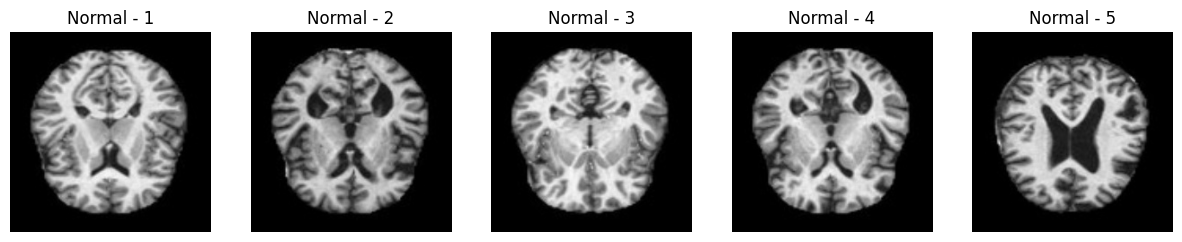

Visualizing images from Alzheimers


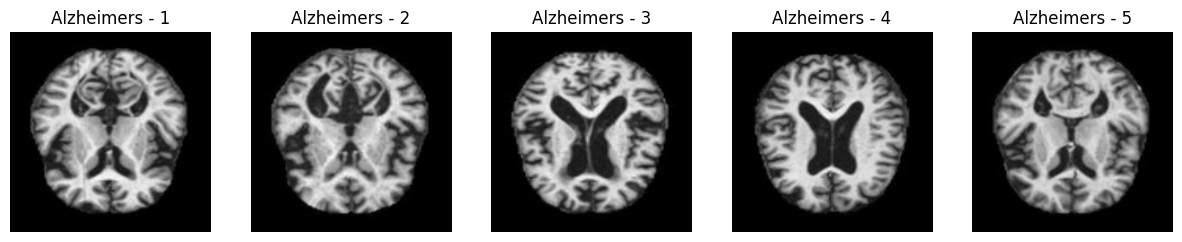

Visualizing images from Parkinson


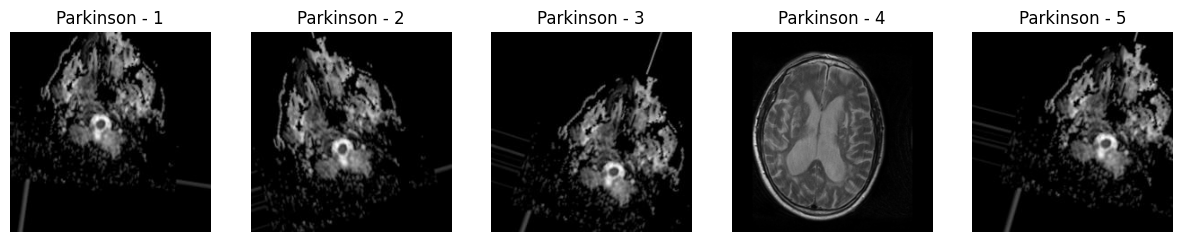

Data preprocessing and splitting completed.


In [6]:
# Process each category
for category, source_dir in [('Normal', normal_dir), ('Alzheimers', alzheimers_dir), ('Parkinson', parkinsons_dir)]:
    train_dest = os.path.join(train_dir, category)
    val_dest = os.path.join(val_dir, category)
    test_dest = os.path.join(test_dir, category)
    
    split_data(source_dir, train_dest, val_dest, test_dest)
    preprocess_images(train_dest, train_dest)
    preprocess_images(val_dest, val_dest)
    preprocess_images(test_dest, test_dest)

    # Visualize sample images
    print(f"Visualizing images from {category}")
    visualize_images(category, train_dest)

print("Data preprocessing and splitting completed.")

> # **Data Augmentation and Normalization**
# *I set up data augmentation and normalization using Keras' ImageDataGenerator to improve the model's robustness by applying random transformations to the training images.*

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Paths to the processed data directories
train_dir = 'train'
val_dir = 'validation'
test_dir = 'test'

# Data augmentation and normalization
# Augmentation helps improve the model's robustness by randomly transforming images during training
train_datagen = ImageDataGenerator(
    rescale=1./255,  # Normalize pixel values to [0, 1]
    shear_range=0.2,  # Randomly shear images
    zoom_range=0.2,  # Randomly zoom into images
    horizontal_flip=True,  # Randomly flip images horizontally
    rotation_range=20,  # New augmentation: Rotate images
    width_shift_range=0.2,  # New augmentation: Shift images horizontally
    height_shift_range=0.2,  # New augmentation: Shift images vertically
    brightness_range=[0.8, 1.2]  # New augmentation: Adjust brightness
)

# Only normalization is applied to validation and test sets
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Create data generators
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),  # Resize images to 224x224 pixels
    batch_size=32,  # Number of images to process in a batch
    class_mode='categorical'  # Use categorical labels (one-hot encoding)
)

validation_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

Found 5311 images belonging to 3 classes.
Found 1139 images belonging to 3 classes.


In [3]:
# Check if GPU is available
physical_devices = tf.config.list_physical_devices('GPU')
if physical_devices:
    print(f"Using GPU: {physical_devices[0]}")
else:
    print("No GPU found. Using CPU.")

No GPU found. Using CPU.


In [4]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Paths to the processed data directories
train_dir = 'train'
val_dir = 'validation'
test_dir = 'test'

# Data Augmentation and Normalization for training data
train_datagen = ImageDataGenerator(
    rescale=1./255,  # Normalize pixel values to [0, 1]
    shear_range=0.2,  # Randomly shear images
    zoom_range=0.2,  # Randomly zoom into images
    horizontal_flip=True,  # Randomly flip images horizontally
    rotation_range=20,  # Rotate images randomly
    width_shift_range=0.2,  # Shift images horizontally
    height_shift_range=0.2,  # Shift images vertically
    brightness_range=[0.8, 1.2]  # Adjust brightness of images
)

# Normalization for validation and test data
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Create data generators for training, validation, and testing
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),  # Resize images to 224x224 pixels
    batch_size=32,
    class_mode='categorical'  # Multi-class classification (one-hot encoding)
)

validation_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'  # Multi-class classification (one-hot encoding)
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # Shuffle = False to maintain correct order for evaluation
)


Found 5311 images belonging to 3 classes.
Found 1139 images belonging to 3 classes.
Found 1140 images belonging to 3 classes.


Found 5311 images belonging to 3 classes.
Found 1139 images belonging to 3 classes.
Found 1140 images belonging to 3 classes.


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │         3,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,572,803 (13.63 MB)

 Trainable params: 1,314,819 (5.02 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/20
165/165 ━━━━━━━━━━━━━━━━━━━━ 385s 2s/step - accuracy: 0.6755 - loss: 0.6607 - val_accuracy: 0.8018 - val_loss: 0.3901 - learning_rate: 1.0000e-04
Epoch 2/20
  1/165 ━━━━━━━━━━━━━━━━━━━━ 1:18 480ms/step - accuracy: 0.7500 - loss: 0.3845

c:\ProgramData\anaconda3\Lib\contextlib.py:158: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(value)


165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7500 - loss: 0.3845 - val_accuracy: 0.7368 - val_loss: 0.4601 - learning_rate: 1.0000e-04
Epoch 3/20
165/165 ━━━━━━━━━━━━━━━━━━━━ 298s 2s/step - accuracy: 0.7760 - loss: 0.4416 - val_accuracy: 0.8152 - val_loss: 0.3637 - learning_rate: 1.0000e-04
Epoch 4/20
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6562 - loss: 0.5453 - val_accuracy: 0.6842 - val_loss: 0.4555 - learning_rate: 1.0000e-04
Epoch 5/20
165/165 ━━━━━━━━━━━━━━━━━━━━ 317s 2s/step - accuracy: 0.8035 - loss: 0.3892 - val_accuracy: 0.8348 - val_loss: 0.3501 - learning_rate: 1.0000e-04
Epoch 6/20
165/165 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9062 - loss: 0.2681 - val_accuracy: 0.8947 - val_loss: 0.2435 - learning_rate: 1.0000e-04
Epoch 7/20
165/165 ━━━━━━━━━━━━━━━━━━━━ 321s 2s/step - accuracy: 0.8296 - loss: 0.3553 - val_accuracy: 0.8384 - val_loss: 0.3434 - learning_rate: 1.0000e-04
Epoch 8/20
165/165 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7188 -

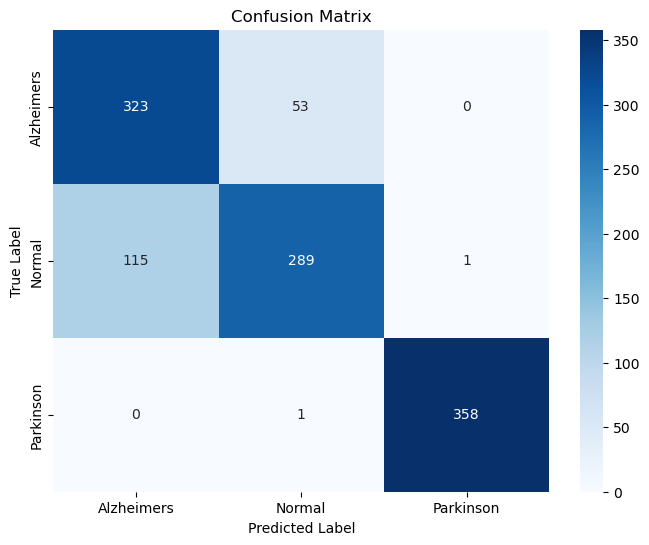

Classification Report
              precision    recall  f1-score   support

  Alzheimers       0.74      0.86      0.79       376
      Normal       0.84      0.71      0.77       405
   Parkinson       1.00      1.00      1.00       359

    accuracy                           0.85      1140
   macro avg       0.86      0.86      0.85      1140
weighted avg       0.86      0.85      0.85      1140



In [10]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Paths to the processed data directories
train_dir = 'train'
val_dir = 'validation'
test_dir = 'test'

# Data Augmentation and Normalization for training data
train_datagen = ImageDataGenerator(
    rescale=1./255,  # Normalize pixel values to [0, 1]
    shear_range=0.2,  # Randomly shear images
    zoom_range=0.2,  # Randomly zoom into images
    horizontal_flip=True,  # Randomly flip images horizontally
    rotation_range=20,  # Rotate images randomly
    width_shift_range=0.2,  # Shift images horizontally
    height_shift_range=0.2,  # Shift images vertically
    brightness_range=[0.8, 1.2]  # Adjust brightness of images
)

# Normalization for validation and test data
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Create data generators for training, validation, and testing
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),  # Resize images to 224x224 pixels
    batch_size=32,
    class_mode='categorical'  # Multi-class classification (one-hot encoding)
)

validation_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'  # Multi-class classification (one-hot encoding)
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # Shuffle = False to maintain correct order for evaluation
)

# Use MobileNetV2 for transfer learning (pre-trained on ImageNet)
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')

# Freeze the base model layers so that they aren't trained initially
base_model.trainable = False

# Define the CNN model with improvements
model = Sequential([
    base_model,  # Add pre-trained MobileNetV2 base model
    GlobalAveragePooling2D(),  # Pooling to reduce dimensionality
    Dense(1024, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')  # Output layer for 3 classes: Normal, Alzheimers, Parkinson
])

# Compile the model with Adam optimizer
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Print the model summary to check the architecture
model.summary()

# Early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Reduce learning rate when validation accuracy plateaus
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

# Save the best model based on validation accuracy
model_checkpoint = ModelCheckpoint("best_model.keras", monitor="val_accuracy", save_best_only=True)

# Train the model
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,  # Adjust the number of epochs as needed
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    callbacks=[early_stopping, lr_scheduler, model_checkpoint]
)

# Fine-tuning: Unfreeze the base model and retrain with a lower learning rate
base_model.trainable = True  # Unfreeze all layers of the base model
for layer in base_model.layers[:100]:  # Optionally, unfreeze only the last few layers
    layer.trainable = False

# Recompile the model after unfreezing some layers
model.compile(
    optimizer=Adam(learning_rate=0.00001),  # Lower learning rate for fine-tuning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Fine-tune the model
history_finetune = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10,  # Fine-tune for a few more epochs
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    callbacks=[early_stopping, lr_scheduler, model_checkpoint]
)

# Save the final fine-tuned model
model.save("fine_tuned_cnn_model.keras")

# Evaluate the model on the test set
y_true = test_generator.classes

# Predict the labels on the test set
steps = int(np.ceil(test_generator.samples / test_generator.batch_size))
y_pred = model.predict(test_generator, steps=steps)

# Convert predictions to class labels
y_pred_classes = np.argmax(y_pred, axis=1)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=test_generator.class_indices.keys(),
            yticklabels=test_generator.class_indices.keys())
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print('Classification Report')
target_names = list(test_generator.class_indices.keys())  # Get the class labels
print(classification_report(y_true, y_pred_classes, target_names=target_names))


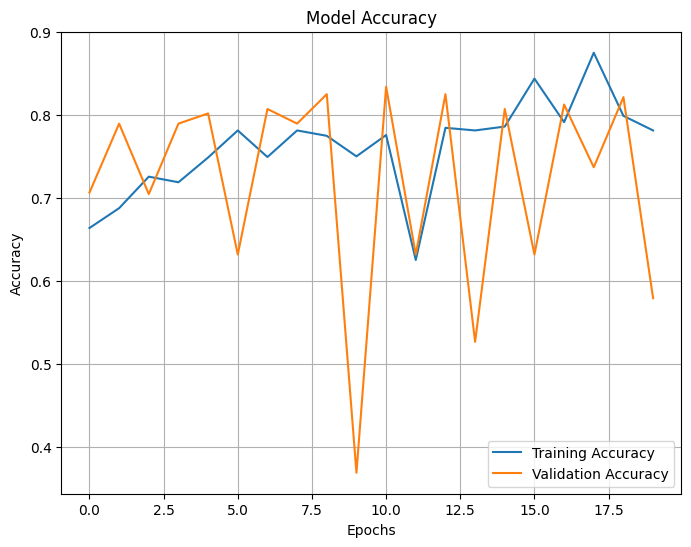

In [15]:
import matplotlib.pyplot as plt

# Assuming 'history' is the History object returned by model.fit()

# Plotting training & validation accuracy values
plt.figure(figsize=(8, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 112, 112, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 112, 112, 64)   │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 113, 113, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 56, 56, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 56, 56, 128)    │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 56, 56, 128)    │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 56, 56, 128)    │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 4,281,539 (16.33 MB)

 Trainable params: 1,052,675 (4.02 MB)

 Non-trainable params: 3,228,864 (12.32 MB)

Epoch 1/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 72s 386ms/step - AUC: 0.5106 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - accuracy: 0.3420 - loss: 1.0984 - val_AUC: 0.5210 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.3562 - val_loss: 1.0977
Epoch 2/30
  1/165 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - AUC: 0.5000 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - accuracy: 0.4062 - loss: 1.0984

/opt/conda/lib/python3.10/contextlib.py:153: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)


165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - AUC: 0.5000 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - accuracy: 0.4062 - loss: 1.0984 - val_AUC: 0.4737 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.3158 - val_loss: 1.1001
Epoch 3/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 63s 368ms/step - AUC: 0.5230 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - accuracy: 0.3530 - loss: 1.0976 - val_AUC: 0.5196 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.3545 - val_loss: 1.0975
Epoch 4/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 477us/step - AUC: 0.4688 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - accuracy: 0.3125 - loss: 1.1016 - val_AUC: 0.5526 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.4211 - val_loss: 1.0943
Epoch 5/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 63s 367ms/step - AUC: 0.5254 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - accuracy: 0.3605 - loss: 1.0970 - val_AUC: 0.5201 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accurac

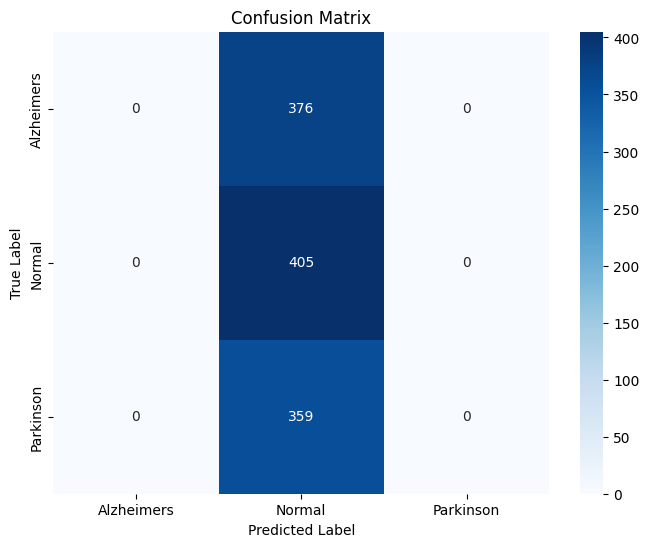

Classification Report
              precision    recall  f1-score   support

  Alzheimers       0.00      0.00      0.00       376
      Normal       0.36      1.00      0.52       405
   Parkinson       0.00      0.00      0.00       359

    accuracy                           0.36      1140
   macro avg       0.12      0.33      0.17      1140
weighted avg       0.13      0.36      0.19      1140



/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [20]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Define the MobileNet model without the top layer
base_model = MobileNet(weights=None, include_top=False, input_shape=(224, 224, 3))

# Add custom layers on top of MobileNet
x = base_model.output
x = GlobalAveragePooling2D()(x)  # Global average pooling layer

# Add dropout to reduce overfitting
x = Dropout(0.5)(x)

# Fully connected layer
x = Dense(1024, activation='relu')(x)

# Output layer (adjust the number of neurons based on the number of classes)
predictions = Dense(3, activation='softmax')(x)  # 3 classes (Normal, Pneumonia-Bacterial, Pneumonia-Viral)

# Define the complete model
model = Model(inputs=base_model.input, outputs=predictions)

# Freeze the layers of MobileNet to retain pre-trained weights
for layer in base_model.layers:
    layer.trainable = False

# Compile the model with Adam optimizer and relevant metrics
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy', 'AUC', 'Precision', 'Recall']
)

# Print the model summary to check the architecture
model.summary()

# Early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Train the model
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=30,  # You can adjust the number of epochs
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    callbacks=[early_stopping]
)

# Evaluate the model on the test set
y_true = test_generator.classes
steps = int(np.ceil(test_generator.samples / test_generator.batch_size))

# Predict the labels on the test set
y_pred = model.predict(test_generator, steps=steps)

# Convert predictions to class labels
y_pred_classes = np.argmax(y_pred, axis=1)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=test_generator.class_indices.keys(),
            yticklabels=test_generator.class_indices.keys())
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print('Classification Report')
target_names = list(test_generator.class_indices.keys())  # Get the class labels
print(classification_report(y_true, y_pred_classes, target_names=target_names))

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 1, 86528)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 256)            │    88,867,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1024)           │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 3)              │         3,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,227,331 (340.38 MB)

 Trainable params: 89,227,331 (340.38 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
165/165 ━━━━━━━━━━━━━━━━━━━━ 69s 385ms/step - AUC: 0.7780 - Precision: 0.6051 - Recall: 0.3590 - accuracy: 0.5527 - loss: 0.7960 - val_AUC: 0.9214 - val_Precision: 0.7699 - val_Recall: 0.7411 - val_accuracy: 0.7634 - val_loss: 0.5495
Epoch 2/20
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8323 - Precision: 0.5667 - Recall: 0.5312 - accuracy: 0.5938 - loss: 0.6497 - val_AUC: 0.9654 - val_Precision: 0.7368 - val_Recall: 0.7368 - val_accuracy: 0.7368 - val_loss: 0.3815
Epoch 3/20
165/165 ━━━━━━━━━━━━━━━━━━━━ 64s 374ms/step - AUC: 0.8988 - Precision: 0.7147 - Recall: 0.6899 - accuracy: 0.7066 - loss: 0.5369 - val_AUC: 0.9254 - val_Precision: 0.7674 - val_Recall: 0.7598 - val_accuracy: 0.7634 - val_loss: 0.4799
Epoch 4/20
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 380us/step - AUC: 0.9509 - Precision: 0.8750 - Recall: 0.8750 - accuracy: 0.8750 - loss: 0.4215 - val_AUC: 0.9030 - val_Precision: 0.6842 - val_Recall: 0.6842 - val_accuracy: 0.6842 - val_loss: 0.5501
Epoch 5/20
165/165 ━━━━━

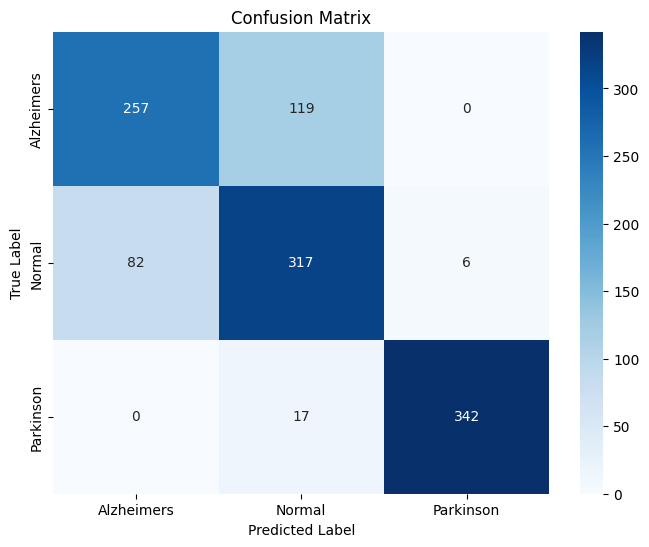

Classification Report
              precision    recall  f1-score   support

  Alzheimers       0.76      0.68      0.72       376
      Normal       0.70      0.78      0.74       405
   Parkinson       0.98      0.95      0.97       359

    accuracy                           0.80      1140
   macro avg       0.81      0.81      0.81      1140
weighted avg       0.81      0.80      0.80      1140



In [26]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, LSTM, GlobalAveragePooling2D, Reshape
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define the CNN part of the model using the functional API
input_tensor = tf.keras.Input(shape=(224, 224, 3))  # Define input shape
x = Conv2D(32, (3, 3), activation='relu')(input_tensor)
x = MaxPooling2D(pool_size=(2, 2))(x)

x = Conv2D(64, (3, 3), activation='relu')(x)
x = MaxPooling2D(pool_size=(2, 2))(x)

x = Conv2D(128, (3, 3), activation='relu')(x)
x = MaxPooling2D(pool_size=(2, 2))(x)

# Flatten layer to convert the 2D matrix to a 1D vector
x = Flatten()(x)

# Add an LSTM layer on top of the CNN features
x = Reshape((1, x.shape[1]))(x)  # Reshaping to match the input shape for LSTM

# LSTM layer
x = LSTM(256, return_sequences=False)(x)  # 256 units

# Fully connected layers
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)

# Output layer (adjust the number of neurons based on the number of classes)
predictions = Dense(3, activation='softmax')(x)  # 3 classes (Normal, Pneumonia-Bacterial, Pneumonia-Viral)

# Define the complete model
model = Model(inputs=input_tensor, outputs=predictions)

# Compile the model with Adam optimizer and relevant metrics
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy', 'AUC', 'Precision', 'Recall']
)

# Print the model summary to check the architecture
model.summary()

# Early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Train the model
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,  # You can adjust the number of epochs as needed
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    callbacks=[early_stopping]
)

# Evaluate the hybrid model on the test set
y_true = test_generator.classes
steps = int(np.ceil(test_generator.samples / test_generator.batch_size))

# Predict the labels on the test set
y_pred = model.predict(test_generator, steps=steps)

# Convert predictions to class labels
y_pred_classes = np.argmax(y_pred, axis=1)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=test_generator.class_indices.keys(),
            yticklabels=test_generator.class_indices.keys())
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print('Classification Report')
target_names = list(test_generator.class_indices.keys())  # Get the class labels
print(classification_report(y_true, y_pred_classes, target_names=target_names))


In [27]:
model.save("hybrid_model.h5")

In [30]:
import os
from IPython.display import HTML

folder_path = '/kaggle/working/'

# List files and directories in the folder
file_list = os.listdir(folder_path)

# Generate hyperlinks for each file/folder
links = [f'<a href="file://{os.path.join(folder_path, file)}" target="_blank">{file}</a><br>' for file in file_list]

# Display all hyperlinks
HTML(''.join(links))


In [ ]:
import shutil

# Path to the folder
folder_path = '/kaggle/working/processed_data'

# Create a zip archive of the folder
shutil.make_archive('/kaggle/working/processed_data_download', 'zip', folder_path)

# Create the download link for the zipped folder
download_link = '/kaggle/working/processed_data_download.zip'

from IPython.display import HTML

# Generate a clickable link for downloading the zipped folder
HTML(f'<a href="{download_link}" download>Click here to download the images in processed_data folder</a>')
